# 데이터로 읽는 소비자 마음: 쇼핑몰 구매 전환 예측

쇼핑몰에 방문한 사람이 구매까지 이어질지, 방문 기록에서 단서를 찾아봤습니다. 상품 페이지를 얼마나 살펴봤는지, 얼마나 머물렀는지, 어떤 환경에서 접속했는지를 이용해 **구매 여부**를 예측했습니다.

이번 데이터는 **방문이 끝난 뒤 정리된 기록**입니다. 따라서 결과는 과거 방문의 구매 여부를 구분한 성능으로 읽어 주세요. 방문 도중 구매를 예측하는 서비스에 쓰려면, 그 시점에 알 수 있었던 정보만으로 다시 평가해야 합니다. 거래 가치에서 계산되는 `PageValues`는 입력에서 제외했습니다.

이 노트북에서는 데이터를 정리하고, 모델을 비교하고, 틀린 사례를 살펴본 뒤 직접 값을 넣어 예측해 보겠습니다. 저장소 폴더에서 순서대로 실행해 주세요. 학습 셀을 실행하면 보고서와 모델 파일도 다시 만들어집니다.

프로젝트를 내려받은 뒤 저장소 루트나 `notebooks/`에서 시작할 수 있습니다. 코드·모델·평가 결과는 각 역할에 맞는 폴더에서 읽고 저장합니다.

In [1]:
import sys
from pathlib import Path

# 저장소 루트와 notebooks 폴더 어느 쪽에서 시작해도 같은 파일을 찾습니다.
ROOT = Path.cwd()
if not (ROOT/'src'/'train.py').is_file():
    ROOT = ROOT.parent
if not (ROOT/'src'/'train.py').is_file():
    raise RuntimeError('저장소 루트 또는 notebooks 폴더에서 노트북을 실행해 주세요.')
sys.path.insert(0, str(ROOT/'src'))
from paths import REPORTS_DIR, FIGURES_DIR, MODELS_DIR, EXAMPLES_DIR, DOCS_DIR

from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from train import load_data, split_data, train
from predict import predict
from reporting import (FEATURE_LABELS, METRIC_LABELS, comparison_for_readers,
                       importance_for_readers, errors_for_readers)
import joblib

# 입력에 쓰는 영문 열 이름은 유지하고, 표를 보여 줄 때만 한국어 이름을 붙입니다.
X, y, audit = load_data()
audit_labels = {'raw_rows':'원본 기록 수', 'rows':'정리한 뒤 기록 수', 'duplicates_removed':'중복으로 정리한 기록 수', 'conflicting_rows_removed':'같은 입력에 정답이 달라 제외한 기록 수', 'missing_cells':'비어 있는 값의 수', 'positive_rate':'찾으려는 대상의 비율'}
display(pd.Series({label:audit[key] for key,label in audit_labels.items()}).to_frame('데이터 확인'))
display(X.head().rename(columns=FEATURE_LABELS))


,데이터 확인
원본 기록 수,12330.000000
정리한 뒤 기록 수,12205.000000
중복으로 정리한 기록 수,125.000000
같은 입력에 정답이 달라 제외한 기록 수,0.000000
비어 있는 값의 수,0.000000
찾으려는 대상의 비율,0.156329


,관리 페이지 방문 수,관리 페이지 체류 시간,정보 페이지 방문 수,정보 페이지 체류 시간,상품 페이지 방문 수,상품 페이지 체류 시간,반송률,이탈률,특별한 날과의 근접도,방문 월,운영체제,브라우저,지역,유입 경로,방문자 유형,주말 여부
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,Feb,3,3,1,4,Returning_Visitor,True


## 1. 자료를 나누고 분포를 살펴보겠습니다

먼저 같은 기록이 반복되어 있지 않은지 정리합니다. 그런 다음 학습 60%, 검증 20%, 테스트 20%로 나누겠습니다. 학습 자료는 모델을 만드는 데, 검증 자료는 모델과 판단 기준을 고르는 데, 테스트 자료는 마지막 성능 확인에 씁니다. 아래 분포표에서는 학습 자료만 살펴보겠습니다.

In [2]:
Xtr, Xv, Xt, ytr, yv, yt = split_data(X, y)
display(pd.DataFrame({'기록 수':[len(Xtr),len(Xv),len(Xt)],
                      '찾으려는 대상의 비율':[ytr.mean(),yv.mean(),yt.mean()]},
                     index=['학습','검증','테스트']))
statistics = Xtr.describe(include='all').T.rename(index=FEATURE_LABELS)
display(statistics.rename(columns={'count':'개수','mean':'평균','std':'표준편차',
    'min':'최솟값','25%':'하위 25%','50%':'중앙값','75%':'하위 75%','max':'최댓값',
    'unique':'서로 다른 값의 수','top':'가장 흔한 값','freq':'가장 흔한 값의 개수'}))

,기록 수,찾으려는 대상의 비율
학습,7323,0.156357
검증,2441,0.156084
테스트,2441,0.156493


,개수,서로 다른 값의 수,가장 흔한 값,가장 흔한 값의 개수,평균,표준편차,최솟값,하위 25%,중앙값,하위 75%,최댓값
관리 페이지 방문 수,7323.0,NaN,NaN,NaN,2.360508,3.367832,0.0,0.0,1.0,4.0,27.0
관리 페이지 체류 시간,7323.0,NaN,NaN,NaN,83.189051,182.205375,0.0,0.0,9.0,95.3,3398.75
정보 페이지 방문 수,7323.0,NaN,NaN,NaN,0.508944,1.283293,0.0,0.0,0.0,0.0,24.0
정보 페이지 체류 시간,7323.0,NaN,NaN,NaN,34.281107,140.13711,0.0,0.0,0.0,0.0,2549.375
상품 페이지 방문 수,7323.0,NaN,NaN,NaN,31.98812,44.634498,0.0,8.0,18.0,38.0,705.0
상품 페이지 체류 시간,7323.0,NaN,NaN,NaN,1208.663839,1962.53821,0.0,194.625,612.625,1489.848611,63973.52223
반송률,7323.0,NaN,NaN,NaN,0.020446,0.045714,0.0,0.0,0.002778,0.016573,0.2
이탈률,7323.0,NaN,NaN,NaN,0.041737,0.046535,0.0,0.014286,0.025,0.05,0.2
특별한 날과의 근접도,7323.0,NaN,NaN,NaN,0.062515,0.199829,0.0,0.0,0.0,0.0,1.0
방문 월,7323,10,May,2007,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. 여러 모델을 같은 조건에서 학습해 보겠습니다

수치 범위를 맞추기 전후의 로지스틱 회귀와, 깊이를 달리한 의사결정나무를 비교하겠습니다. 쇼핑몰 데이터에서는 랜덤 포레스트도 함께 비교합니다.

우리가 찾는 대상이 적기 때문에 정확도만 보지는 않겠습니다. 검증 AP가 가장 높은 모델을 고르고, 그 모델의 검증 F1이 가장 높은 임계값을 찾겠습니다. 테스트 자료는 이 선택이 모두 끝난 다음에 확인합니다.

In [3]:
result = train()

학습과 평가를 마쳤습니다. 선택한 모델: 랜덤 포레스트 / 임계값: 0.20
자세한 수치와 해석은 docs/evaluation.md에서 확인할 수 있습니다.


,모델,학습 F1,검증 F1,검증 AP,테스트 정확도,테스트 F1
0,다수 클래스만 예측하는 기준 모델,0.000000,0.000000,0.156084,0.843507,0.000000
1,로지스틱 회귀 · 표준화 전,0.052980,0.045113,0.316980,0.843097,0.054321
2,로지스틱 회귀 · 표준화 후,0.057851,0.044665,0.341648,0.844326,0.064039
3,의사결정나무 · 깊이 3,0.000000,0.000000,0.276464,0.843507,0.000000
4,의사결정나무 · 깊이 5,0.196959,0.152174,0.329403,0.835313,0.162500
5,의사결정나무 · 깊이 8,0.359578,0.201942,0.319573,0.827530,0.244165
6,깊이 제한 없는 나무 · 비교용,1.000000,0.260645,0.182662,0.768947,0.282443
7,랜덤 포레스트,0.059272,0.010417,0.368365,0.844736,0.020672


,임계값,정확도,정밀도,재현율,F1,ROC-AUC,AP
0,0.10,0.474396,0.221261,0.939633,0.358179,0.776434,0.368365
1,0.15,0.621057,0.269882,0.837270,0.408189,0.776434,0.368365
2,0.20,0.725932,0.314433,0.640420,0.421780,0.776434,0.368365
3,0.25,0.802540,0.372152,0.385827,0.378866,0.776434,0.368365
4,0.30,0.827939,0.406699,0.223097,0.288136,0.776434,0.368365
5,0.35,0.845555,0.517857,0.152231,0.235294,0.776434,0.368365
6,0.40,0.849652,0.640000,0.083990,0.148492,0.776434,0.368365
7,0.45,0.844736,0.555556,0.026247,0.050125,0.776434,0.368365
8,0.50,0.844326,0.666667,0.005249,0.010417,0.776434,0.368365
9,0.55,0.844326,1.000000,0.002625,0.005236,0.776434,0.368365


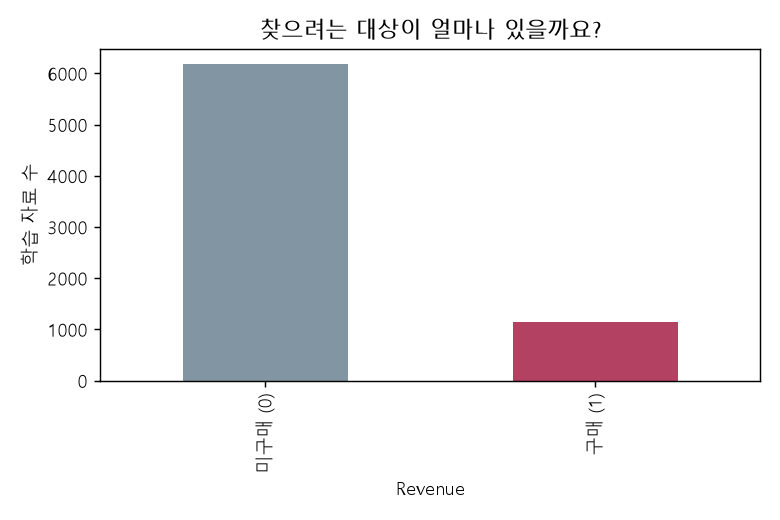

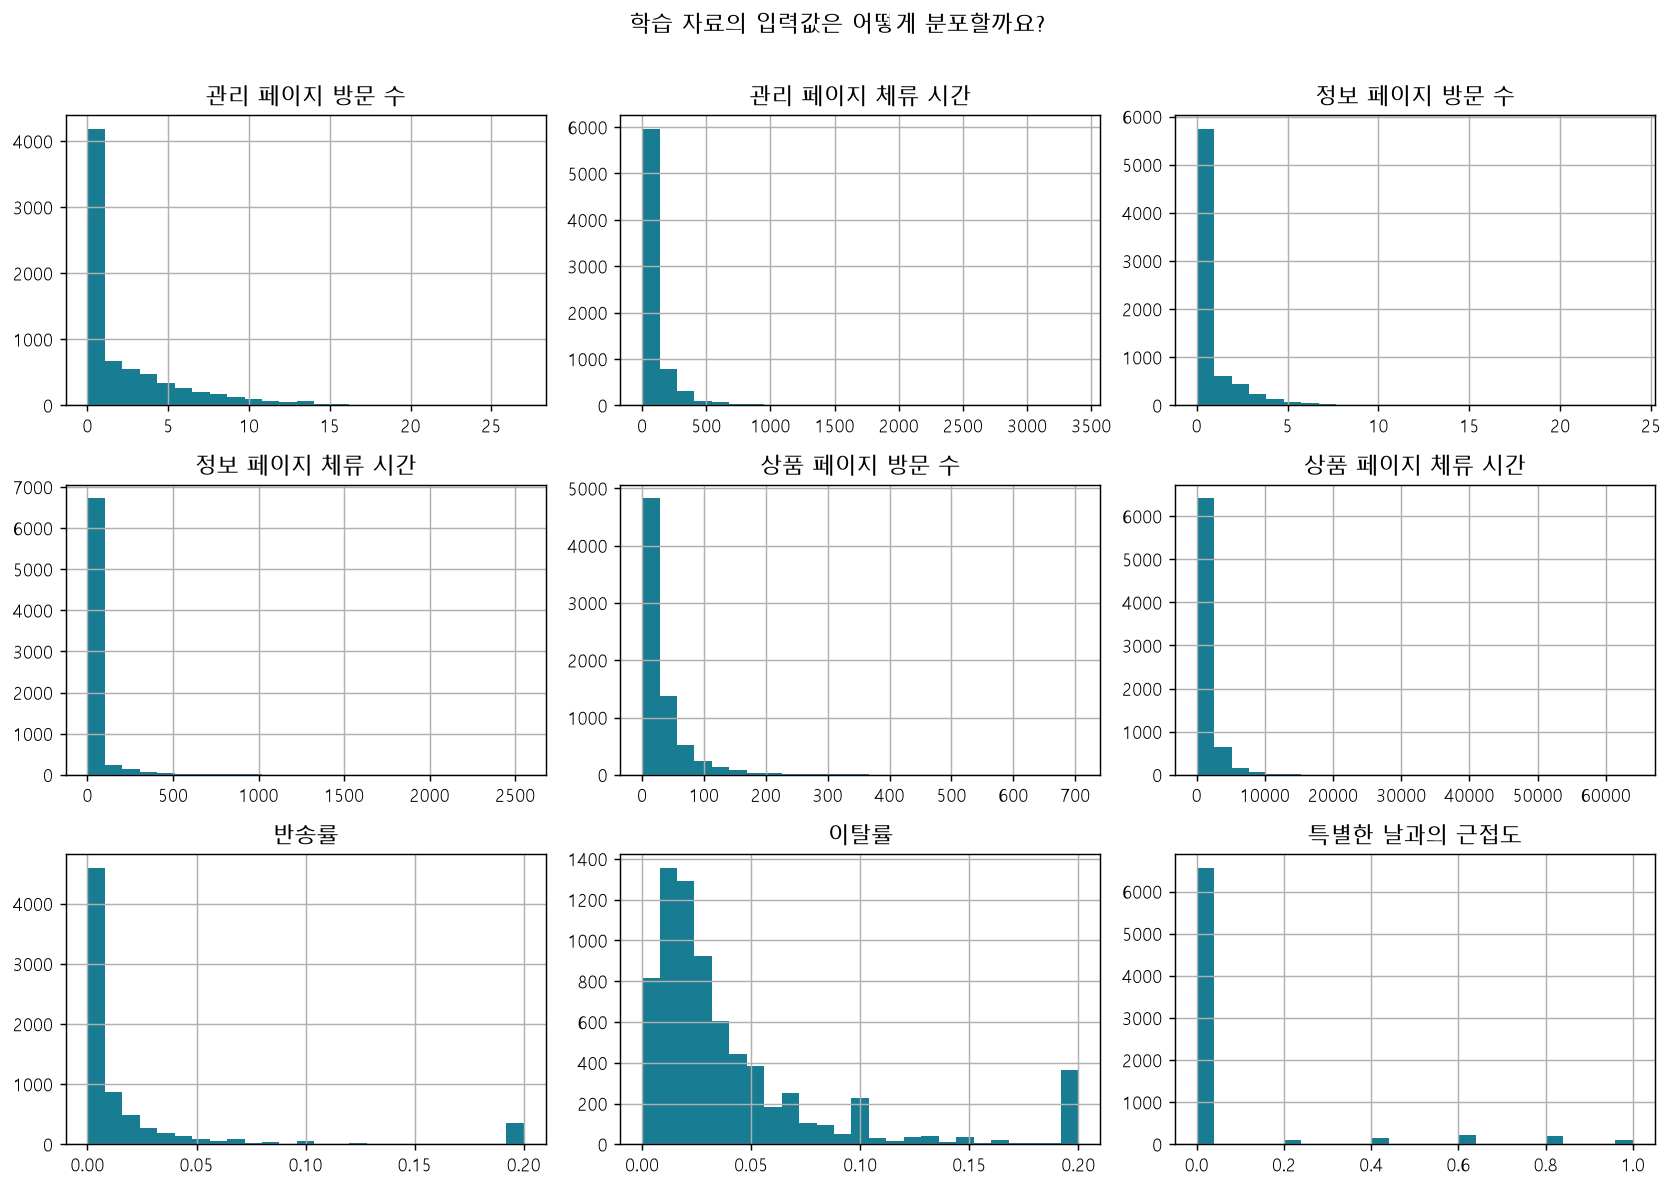

In [4]:
comparison = pd.read_csv(REPORTS_DIR/'model_comparison.csv')
display(comparison_for_readers(comparison))
display(pd.read_csv(REPORTS_DIR/'validation_thresholds.csv').rename(columns={**METRIC_LABELS, 'threshold':'임계값'}))
display(Image(filename=str(FIGURES_DIR/'class_balance.png')))
display(Image(filename=str(FIGURES_DIR/'feature_distributions.png')))

## 3. 맞힌 개수와 놓친 개수를 함께 보겠습니다

혼동 행렬에서 행은 실제 결과, 열은 모델의 예측입니다. 정밀도는 “대상이라고 예측한 것 중 얼마나 맞았는가”, 재현율은 “실제 대상 중 얼마나 찾아냈는가”를 보여 줍니다. 정확도가 높아도 찾고 싶은 대상을 많이 놓칠 수 있어서 함께 살펴보겠습니다.

틀린 사례도 표로 확인해 보겠습니다. 표의 확률은 별도로 보정한 값이 아닙니다.

,최종 테스트 결과
정확도,0.721835
정밀도,0.316893
재현율,0.672775
F1,0.430847
ROC-AUC,0.779358
AP,0.372279


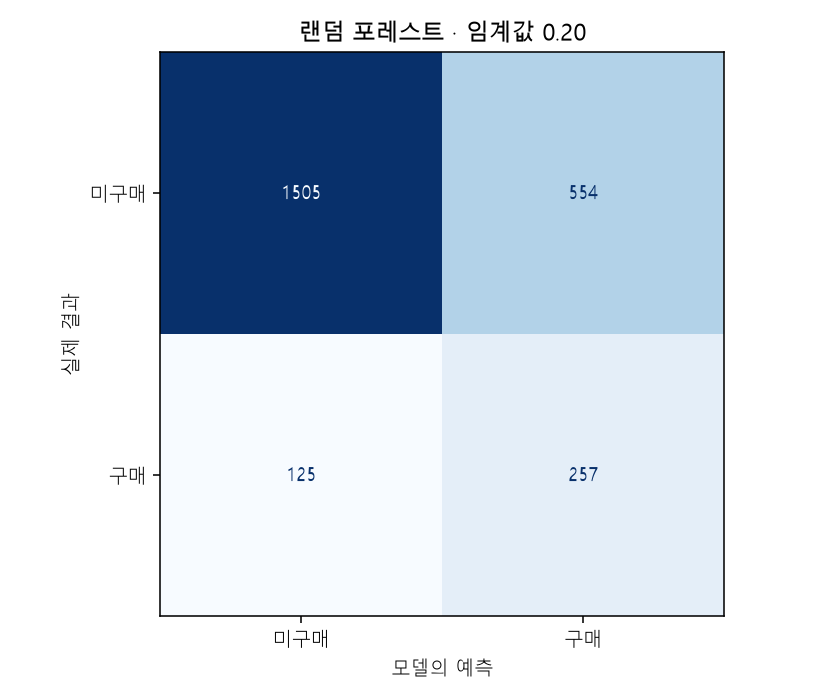

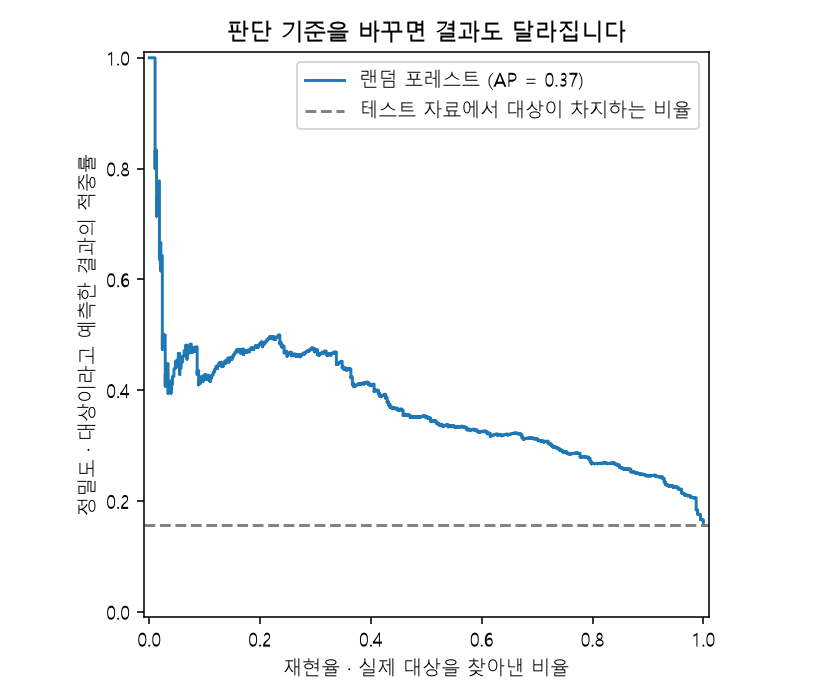

,원본 행 번호,실제 결과,예측 결과,구매 확률,틀린 유형
0,10615,구매,미구매,0.011696,구매 고객을 놓침 (FN)
1,7600,구매,미구매,0.012600,구매 고객을 놓침 (FN)
2,2950,구매,미구매,0.026788,구매 고객을 놓침 (FN)
3,11798,구매,미구매,0.030350,구매 고객을 놓침 (FN)
4,7180,구매,미구매,0.041368,구매 고객을 놓침 (FN)
5,8106,구매,미구매,0.071829,구매 고객을 놓침 (FN)
6,9042,구매,미구매,0.072220,구매 고객을 놓침 (FN)
7,4623,구매,미구매,0.073442,구매 고객을 놓침 (FN)
8,7497,구매,미구매,0.076011,구매 고객을 놓침 (FN)
9,2785,구매,미구매,0.080011,구매 고객을 놓침 (FN)


In [5]:
display(pd.Series(result['test']).rename(index=METRIC_LABELS).to_frame('최종 테스트 결과'))
display(Image(filename=str(FIGURES_DIR/'confusion_matrix.png')))
display(Image(filename=str(FIGURES_DIR/'precision_recall.png')))
display(errors_for_readers(pd.read_csv(REPORTS_DIR/'misclassified.csv').head(10), False))

## 4. 모델이 주로 참고한 항목을 찾아보겠습니다

검증 자료에서 입력 항목을 하나씩 무작위로 섞고 AP가 얼마나 떨어지는지 8번 확인했습니다. 많이 떨어질수록 모델이 그 항목에 의존했다는 뜻입니다. 다만 “중요한 항목을 바꾸면 결과도 좋아진다”는 인과관계까지 보여 주지는 않습니다.

,입력 항목,AP 감소량 평균,AP 감소량 표준편차
0,방문 월 (Month),0.061353,0.008163
1,상품 페이지 체류 시간 (ProductRelated_Duration),0.035559,0.008418
2,이탈률 (ExitRates),0.031731,0.010063
3,방문자 유형 (VisitorType),0.023585,0.005156
4,반송률 (BounceRates),0.011415,0.005353
5,상품 페이지 방문 수 (ProductRelated),0.009963,0.010112
6,유입 경로 (TrafficType),0.008523,0.004306
7,관리 페이지 방문 수 (Administrative),0.004823,0.008622
8,지역 (Region),0.003829,0.002300
9,운영체제 (OperatingSystems),0.000988,0.001709


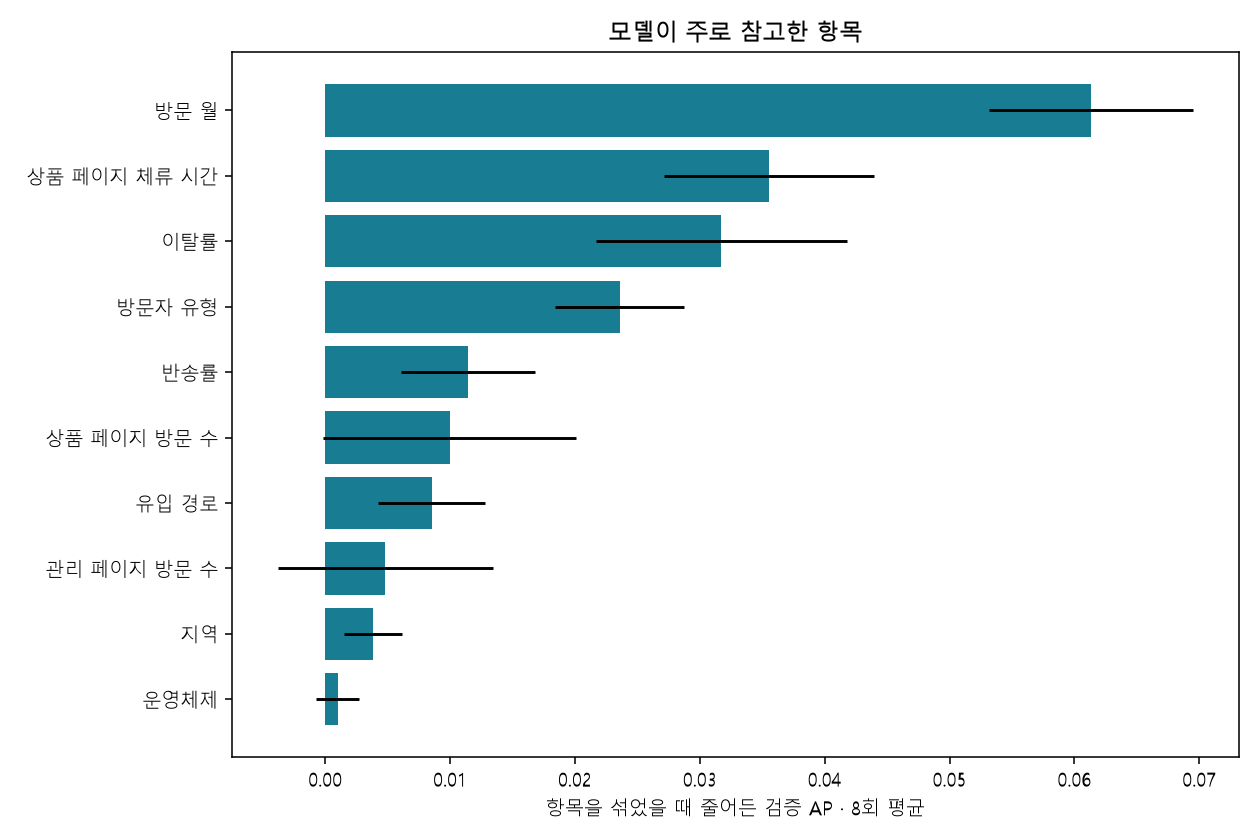

In [6]:
display(importance_for_readers(pd.read_csv(REPORTS_DIR/'feature_importance.csv')))
display(Image(filename=str(FIGURES_DIR/'feature_importance.png')))

## 5. 직접 값을 넣어 예측해 보겠습니다

`examples/sample_input.json`의 값을 바꿔 다른 방문 기록도 시험해 보세요. 항목 이름은 그대로 두고 값만 바꾸면 됩니다. 어떤 열인지 헷갈리면 [입력 항목 안내](../docs/FEATURES.md)를 참고해 주세요. 학습 때 보지 못한 수치 범위가 나오면 결과에 해당 항목이 표시됩니다.

In [7]:
sample = json.loads((EXAMPLES_DIR/'sample_input.json').read_text(encoding='utf-8'))
bundle = joblib.load(MODELS_DIR/'model.joblib')
display(pd.Series(sample).rename(index=FEATURE_LABELS).to_frame('입력값'))
prediction = predict(sample, bundle)
display(pd.Series(prediction).rename(index={'label':'예측 결과','prediction':'예측 코드',
    'positive_probability':'구매할 확률','threshold':'판단 기준(임계값)',
    'outside_training_range':'학습 범위를 벗어난 항목'}).to_frame('예측 확인'))

,입력값
관리 페이지 방문 수,0
관리 페이지 체류 시간,0.0
정보 페이지 방문 수,0
정보 페이지 체류 시간,0.0
상품 페이지 방문 수,10
상품 페이지 체류 시간,126.833333
반송률,0.04
이탈률,0.06
특별한 날과의 근접도,0.0
방문 월,May


,예측 확인
예측 결과,미구매 예상
예측 코드,0
구매할 확률,0.023381
판단 기준(임계값),0.2
학습 범위를 벗어난 항목,[]


## 6. 결과를 문장으로 정리해 보겠습니다

마지막으로 성능 수치가 뜻하는 바와 이번 실험의 한계를 읽어 보겠습니다. 잘 맞힌 부분과 더 확인해야 할 부분을 함께 정리했습니다. 데이터 출처와 이용 조건은 [출처 안내](../docs/DATA_SOURCES.md)에 있습니다.

In [8]:
report_text = (DOCS_DIR/'evaluation.md').read_text(encoding='utf-8')
report_text = report_text.replace('(DATA_SOURCES.md)', '(../docs/DATA_SOURCES.md)')
display(Markdown(report_text))

# 방문 기록에서 찾아본 구매 신호

쇼핑몰에 들어온 사람이 실제로 구매할지, 방문 기록에서 단서를 찾을 수 있는지 살펴봤습니다. 페이지를 얼마나 봤는지, 얼마나 머물렀는지, 어떤 환경에서 접속했는지를 입력하고 **구매 여부**를 예측했습니다. 이 보고서의 결과는 이미 끝난 방문 기록을 분석한 결과입니다.

최종 모델은 **랜덤 포레스트**였습니다. 테스트에서 실제 구매 고객 382명 중 257명을 찾아 재현율은 **67.28%**였습니다. 반면 구매할 것으로 예측한 811명 중 실제 구매자는 257명이라, 정밀도는 **31.69%**였습니다. 구매 고객을 더 찾는 대신 잘못 짚는 경우도 많은 결과입니다.

## 먼저 데이터를 정리했습니다

`Revenue=True`를 구매로 표시했습니다. 접속 환경 코드와 방문 월 등은 숫자 크기에 의미가 없어서 원핫 인코딩으로 바꿨습니다. `PageValues`를 제외한 이유는 아래에서 따로 설명합니다. 원본은 12,330행이었습니다. 입력과 정답이 똑같이 반복된 125행을 정리한 뒤 12,205행으로 실험했습니다. 같은 기록이 학습과 테스트에 나눠 들어가 점수가 부풀려지는 일을 줄이기 위해서입니다. 같은 입력에 서로 다른 정답이 붙어 있는 사례는 중복 정리 후 발견되지 않았습니다.

비어 있는 값은 0개였고, 전체에서 구매한 고객의 비율은 **15.63%**였습니다. 우리가 찾고 싶은 대상이 적다는 점을 염두에 두고 결과를 읽어야 합니다.

## 배울 자료와 시험 볼 자료를 나눴습니다

데이터는 학습 60%, 검증 20%, 테스트 20%로 나눴습니다. 학습 자료로 모델을 만들고, 검증 자료로 모델과 판단 기준을 골랐습니다. 테스트 자료는 이 선택이 모두 끝난 뒤 최종 성능을 확인하는 데만 썼습니다.

| 용도 | 기록 수 |
| --- | --- |
| 모델 학습 | 7,323 |
| 모델·임계값 선택을 위한 검증 | 2,441 |
| 최종 성능 확인 | 2,441 |

각 묶음의 정답 비율이 비슷하도록 층화 분할을 했고, `random_state=42`로 같은 분할을 다시 만들 수 있게 했습니다. 평균·표준편차나 결측값을 채울 기준은 **학습 자료에서만** 구했습니다. 데이터 분포를 그릴 때도 학습 자료만 사용했습니다. 이 과정을 `Pipeline`으로 묶어 테스트 정보가 학습에 섞이지 않게 했습니다.

## 여러 모델을 같은 조건에서 비교했습니다

아래 표는 모두 예측 확률 **0.50 이상**을 구매로 판단했을 때의 결과입니다. F1과 AP는 0~1 사이의 값이며, 클수록 좋습니다.

| 모델 | 학습 F1 | 검증 F1 | 검증 AP | 테스트 정확도 | 테스트 F1 |
| --- | --- | --- | --- | --- | --- |
| 다수 클래스만 예측하는 기준 모델 | 0.0000 | 0.0000 | 0.1561 | 0.8435 | 0.0000 |
| 로지스틱 회귀 · 표준화 전 | 0.0530 | 0.0451 | 0.3170 | 0.8431 | 0.0543 |
| 로지스틱 회귀 · 표준화 후 | 0.0579 | 0.0447 | 0.3416 | 0.8443 | 0.0640 |
| 의사결정나무 · 깊이 3 | 0.0000 | 0.0000 | 0.2765 | 0.8435 | 0.0000 |
| 의사결정나무 · 깊이 5 | 0.1970 | 0.1522 | 0.3294 | 0.8353 | 0.1625 |
| 의사결정나무 · 깊이 8 | 0.3596 | 0.2019 | 0.3196 | 0.8275 | 0.2442 |
| 깊이 제한 없는 나무 · 비교용 | 1.0000 | 0.2606 | 0.1827 | 0.7689 | 0.2824 |
| 랜덤 포레스트 | 0.0593 | 0.0104 | 0.3684 | 0.8447 | 0.0207 |

### 수치 범위를 맞춘 이유

체류 시간이나 성분 농도처럼 입력마다 숫자 크기가 다르면 로지스틱 회귀의 학습과 규제에 영향을 줄 수 있습니다. `StandardScaler`는 학습 자료의 평균과 표준편차를 기준으로 이 범위를 맞춰 줍니다. 의사결정나무는 값을 기준으로 가지를 나누기 때문에 별도로 표준화하지 않았습니다.

로지스틱 회귀의 검증 AP는 표준화 전 0.3170, 표준화 후 0.3416였습니다. 수치 범위를 맞춘 뒤 구매 고객의 순서를 구분하는 성능은 개선됐습니다. 다만 아래 수렴 경고도 함께 고려해야 합니다.

표준화하지 않은 로지스틱 회귀에서는 수렴 경고가 나왔습니다. 반복 계산이 충분히 마무리되지 않았다는 뜻입니다. 따라서 이 점수만으로 모델 자체의 한계를 단정하기는 어렵습니다. 경고 여부는 `reports/model_comparison.csv`에도 남겼습니다.

### 최종 모델과 판단 기준

일반 사례가 많은 데이터라 정확도만 보고 고르지 않았습니다. 검증 자료에서 **AP(Average Precision)**가 가장 높은 모델을 골랐습니다. AP는 우리가 찾는 대상을 예측 확률의 앞쪽에 얼마나 잘 모았는지 살펴보는 지표입니다. 여기서 쓴 AP는 PR 곡선의 넓이를 사다리꼴로 계산한 값과는 계산 방식이 다릅니다.

선택한 모델은 **랜덤 포레스트**(`random_forest`)입니다. 그다음 확률이 얼마 이상일 때 구매로 판단할지, 즉 **임계값**을 검증 자료에서 조정했습니다. 0.10부터 0.90까지 0.05 간격으로 비교해 F1이 가장 높은 **0.20**를 골랐습니다. 동률이면 더 큰 값을 사용했습니다.

깊이 제한 없는 나무는 과적합을 관찰하는 비교용으로만 사용했습니다. 또 검증 자료에서 특성 중요도를 평가하려고, 마지막에 학습·검증 자료를 합쳐 재학습하지는 않았습니다.

## 처음 보는 데이터에서는 이 정도로 맞혔습니다

다음은 선택한 모델에 조정한 임계값 **0.20**를 적용한 결과입니다. 앞의 비교 표는 0.50을 사용했으므로 수치가 다를 수 있습니다.

| 정확도 | 정밀도 | 재현율 | F1 | ROC-AUC | AP |
| --- | --- | --- | --- | --- | --- |
| 72.18% | 31.69% | 67.28% | 0.4308 | 0.7794 | 0.3723 |

모두 미구매로 예측하면 정확도는 84.35%로, 최종 모델의 72.18%보다 높습니다. 하지만 그렇게 하면 구매 고객을 한 명도 찾지 못합니다. 이번에는 검증 F1을 기준으로 구매를 판단하는 문턱을 낮춰 재현율을 높였습니다. 어느 쪽이 사업에 유리한지는 캠페인 비용과 구매 이익까지 알아야 판단할 수 있습니다.

실제 구매 고객 382명 중 257명을 찾았고, 125명은 놓쳤습니다. 구매하지 않은 고객 2,059명 중에서는 554명을 구매할 것으로 잘못 예측했습니다.

**정밀도**는 “구매할 것으로 짚은 고객 중 실제로 맞은 비율”, **재현율**은 “실제 구매 고객 중 찾아낸 비율”입니다. 각각 TP/(TP+FP), TP/(TP+FN)으로 계산합니다.

![실제 결과와 예측 결과를 비교한 혼동 행렬](../figures/confusion_matrix.png)

행은 실제 결과, 열은 모델의 예측입니다. 미구매을 0, 구매를 1로 두었을 때 TN=1505, FP=554, FN=125, TP=257입니다.

![판단 기준에 따라 달라지는 정밀도와 재현율](../figures/precision_recall.png)

## 틀린 사례도 따로 살펴봤습니다

테스트에서 틀린 679건을 `reports/misclassified.csv`에 모았습니다. 원본 행 번호와 입력값, 실제 결과, 예측 결과, 확률을 함께 볼 수 있습니다. 아래는 모델이 0.50에서 가장 멀리 떨어진 확률을 내놓고도 틀린 사례 5건입니다.

| 원본 행 번호 | 실제 결과 | 예측 결과 | 구매 확률 | 틀린 유형 |
| --- | --- | --- | --- | --- |
| 10615 | 구매 | 미구매 | 0.0117 | 구매 고객을 놓침 (FN) |
| 7600 | 구매 | 미구매 | 0.0126 | 구매 고객을 놓침 (FN) |
| 2950 | 구매 | 미구매 | 0.0268 | 구매 고객을 놓침 (FN) |
| 11798 | 구매 | 미구매 | 0.0303 | 구매 고객을 놓침 (FN) |
| 7180 | 구매 | 미구매 | 0.0414 | 구매 고객을 놓침 (FN) |

FP가 많으면 구매하지 않을 고객에게 캠페인 비용을 쓸 수 있고, FN이 많으면 관심을 가져볼 구매 고객을 놓칠 수 있습니다. 표의 확률은 별도로 보정하지 않은 값입니다. 특히 나무 모델의 0이나 1을 절대적인 확신으로 받아들이지는 않는 편이 좋겠습니다.

오답의 원인은 이 표만으로 단정하지 않았습니다. 테스트 오답을 보고 다음 모델을 개선한다면, 그 모델은 새 테스트 자료로 다시 확인해야 합니다.

## 학습 점수만 높으면 생기는 문제

깊이를 제한하지 않은 나무는 학습 F1이 **1.0000**였지만, 검증 F1은 **0.2606**였습니다. 배운 자료를 잘 외우더라도 새로운 자료에서는 잘 맞히지 못할 수 있다는 예입니다. 그래서 깊이를 3·5·8로 제한하고, 마지막 잎에 들어가는 학습 표본도 최소 10개가 되도록 해 비교했습니다.

## 모델이 주로 참고한 항목

입력 항목을 하나씩 무작위로 섞은 뒤 검증 AP가 얼마나 떨어지는지 8번씩 확인했습니다. 이를 **순열 중요도(permutation importance)**라고 합니다. 감소량이 크면, 이 모델이 그 항목에 많이 의존했다는 뜻입니다.

| 입력 항목 | AP 감소량 평균 | AP 감소량 표준편차 |
| --- | --- | --- |
| 방문 월 (Month) | 0.0614 | 0.0082 |
| 상품 페이지 체류 시간 (ProductRelated_Duration) | 0.0356 | 0.0084 |
| 이탈률 (ExitRates) | 0.0317 | 0.0101 |
| 방문자 유형 (VisitorType) | 0.0236 | 0.0052 |
| 반송률 (BounceRates) | 0.0114 | 0.0054 |

![입력 항목을 섞었을 때 성능이 얼마나 떨어졌는지 비교](../figures/feature_importance.png)

방문 월, 상품 페이지 체류 시간, 이탈률이 상위에 나타났습니다. 이를 바탕으로 다음 분석과 실험을 생각해 볼 수 있습니다.

- **방문 월:** 계절이나 캠페인 시기에 따라 패턴이 달라졌을 수 있습니다. 먼저 다른 기간에도 성능이 유지되는지 확인하는 편이 좋겠습니다.
- **상품 페이지 체류 시간:** 오래 머문 이유가 관심인지, 정보를 찾기 어려워서인지 나눠 살펴볼 수 있습니다. 상품 설명이나 검색 기능을 개선한 뒤 A/B 테스트로 구매 변화를 확인해 볼 수 있습니다.
- **이탈률과 방문자 유형:** 고객이 어느 페이지에서 떠나는지, 신규 방문자와 재방문자가 어떤 동선을 거치는지 비교해 볼 수 있습니다.

중요도만으로 어느 집단이 더 잘 구매하는지, 체류 시간을 늘리면 구매가 늘어나는지까지 알 수는 없습니다. 쿠폰 비용과 구매 이익도 없어 예상 매출이나 투자수익률(ROI)은 계산하지 않았습니다.

감소량이 음수인 항목은 이번 실험에서 중요도가 뚜렷하지 않을 수 있습니다. 서로 비슷한 정보를 담은 항목끼리는 중요도를 나눠 가질 수도 있습니다.

## 실제 서비스에 쓰기 전에 확인할 점

`PageValues`는 거래 가치에서 계산되는 지표입니다. 구매 전에 같은 값을 알 수 있는지 확인할 수 없어 이번 입력에서는 제외했습니다. 무조건 데이터 누수라고 단정하기보다는, 예측 시점에 사용할 수 있는지 불확실한 정보를 보수적으로 뺀 것입니다.

체류 시간·반송률·이탈률도 이번 파일에서는 방문이 끝난 뒤의 집계입니다. 따라서 지금 결과를 그대로 “방문 중에 구매를 예측하는 성능”이라고 소개하면 곤란합니다. 실제 서비스에서는 구매 전에 알 수 있었던 정보만 모은 뒤, 이후 기간의 데이터로 다시 평가해야 합니다.

## 여기까지 확인했고, 다음에는 더 확인하고 싶습니다

데이터에 정확한 이벤트 시각이 없어 시간순 평가를 하지 못했습니다. 마케팅에 적용하기 전에는 이후 기간에서의 검증과 A/B 테스트가 필요합니다.

이번에는 한 번의 무작위 분할로 실험해서 분할을 바꾸면 점수가 얼마나 달라지는지, 신뢰구간은 어느 정도인지까지 계산하지 않았습니다. 다음에는 교차검증이나 반복 분할로 결과의 안정성을 확인하고, 예측 확률 보정과 오류 비용을 반영한 임계값 선택도 비교해 보고 싶습니다.

## 같은 결과를 다시 확인하려면

저장소에서 `python src/train.py`를 실행하면 학습과 보고서를 다시 만들 수 있습니다. 데이터 출처와 이용 조건은 [데이터 출처 안내](../docs/DATA_SOURCES.md)에 정리했습니다. 파일별로는 다음 기록을 남겼습니다.

- `reports/split_manifest.csv`: 원본의 어느 행을 학습·검증·테스트에 썼는지
- `reports/metrics.json`: 평가 수치, 실행 버전, 원본 파일의 SHA-256 확인값
- `requirements-lock.txt`: 실험 환경의 패키지 버전

CSV와 JSON의 영문 열 이름은 코드에서 그대로 읽을 수 있도록 유지했습니다. 이 보고서와 노트북에서는 한국어 이름을 덧붙여 설명했습니다.
